In [3]:
import pandas as pd
import pandas as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns



In [4]:
from sklearn .tree import DecisionTreeClassifier
from sklearn .metrics import classification_report

In [5]:
import pandas as pd
import os
file_path=os.path.join(
    os.path.expanduser("~/Downloads"),
    "Combined12.csv"
)

df=pd.read_csv(file_path)


In [6]:
df.head()

,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
0,971.5,0.25,9.0,7.0,10.7,0.0,0,0
1,972.3,0.97,10.5,6.7,13.5,0.0,0,0
2,972.4,0.74,6.5,3.9,9.1,0.0,0,0
3,973.2,0.15,5.1,3.7,7.7,0.0,0,0
4,975.7,0.12,5.2,2.6,8.3,0.0,0,0


In [7]:
df.tail()

,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
533307,1015.0,2.11,19.7,15.0,27.3,3.14,325,0
533308,1015.0,2.11,19.7,15.0,27.3,24.07,147,2
533309,1015.0,2.11,19.7,15.0,27.3,3.30,247,0
533310,1015.0,2.11,19.7,15.0,27.3,25.41,308,2
533311,1015.0,2.11,19.7,15.0,27.3,3.22,190,0


In [8]:
df.shape

(533312, 8)

In [9]:
df.describe()

,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
count,533312.000000,533312.000000,533312.000000,533312.000000,533312.000000,533312.000000,533312.000000,533312.000000
mean,1011.436192,1.310346,12.646057,8.648474,16.871960,11.885974,192.501742,0.906152
std,3.241187,0.897191,6.519240,5.867740,7.692881,7.677086,101.984936,0.992549
min,971.500000,0.030000,-11.100000,-16.000000,-8.500000,0.000000,0.000000,0.000000
25%,1009.800000,0.510000,7.800000,4.500000,11.100000,6.410000,130.000000,0.000000
50%,1012.300000,1.160000,13.200000,9.400000,17.200000,11.040000,190.000000,1.000000
75%,1013.900000,2.010000,17.500000,13.300000,22.400000,15.620000,288.000000,2.000000
max,1015.000000,3.600000,28.600000,22.000000,37.000000,47.530000,359.000000,3.000000


In [11]:
df['normalized_label'].value_counts()


normalized_label
0    239241
1    155709
2     87533
3     50829
Name: count, dtype: int64

In [19]:
co=pd.crosstab(df['Pressure'],df['global_radiation'])
co

global_radiation,0.03,0.04,0.05,0.06,0.07,0.08,0.09,0.10,0.11,0.12,...,3.48,3.49,3.50,3.51,3.52,3.54,3.55,3.56,3.57,3.60
Pressure,,,,,,,,,,,,,,,,,,,,,
971.5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
972.3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
972.4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
973.2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
975.7,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1014.6,0,0,0,0,94,0,94,94,0,94,...,0,0,0,0,0,0,0,0,0,0
1014.7,0,0,0,100,0,0,0,200,100,200,...,0,0,0,100,0,0,0,0,0,0
1014.8,0,0,0,0,0,0,192,0,96,192,...,0,0,0,0,0,0,96,0,0,0


[]

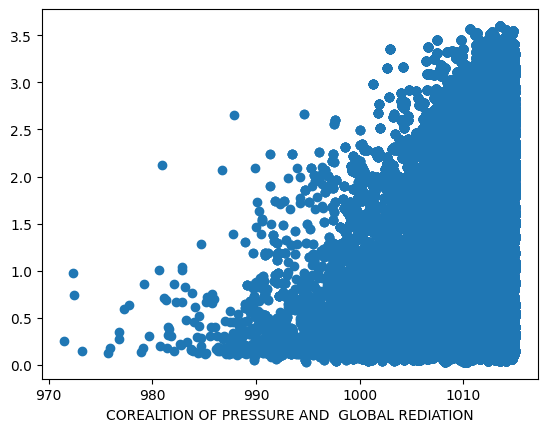

In [24]:
plt.scatter(df['Pressure'],df['global_radiation'])
plt.xlabel("COREALTION OF PRESSURE AND  GLOBAL REDIATION")
plt.plot(kind='line')

In [29]:
x=df.drop(df.iloc[:,0:7],axis=1)
y=df.iloc[:,-1]

In [30]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=7)

In [31]:
dtc=DecisionTreeClassifier()
dtc.fit(x_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [32]:
dtc.score(x_test,y_test)

1.0

In [49]:
dtc.score(x_train,y_train)

1.0

In [ ]:
y_pred=dtc.predict(x_train)


In [51]:
y_pred

array([0, 2, 0, ..., 0, 0, 0], shape=(426649,))

In [50]:
y_pred[:5]

array([0, 2, 0, 0, 0])

In [53]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

ValueError: Found input variables with inconsistent numbers of samples: [106663, 426649]

In [55]:
from sklearn.model_selection import cross_val_score
c_v_a=cross_val_score(dtc,x,y,cv=5,scoring=None)

In [56]:
c_v_a

array([1., 1., 1., 1., 1.])

In [57]:
c_v_a.mean()

np.float64(1.0)

In [59]:
c_v_a=cross_val_score(dtc,x,y,cv=5,scoring="accuracy")
c_v_a.mean()

np.float64(1.0)

In [62]:
c_v_a=cross_val_score(dtc,x,y,cv=5,scoring="f1")
c_v_a

array([nan, nan, nan, nan, nan])